# H06. 앞뒤 사이클끼리 서로 닮았는가 (자기상관)

| 항목 | 내용 |
|---|---|
| 질문 | 각 사이클은 바로 앞 사이클과 비슷할까? |
| 귀무가설 H0 | 사이클 특징값은 서로 독립이다(자기상관 없음) |
| 대립가설 H1 | 자기상관이 있다 |
| 검정 | Ljung-Box (시차 10, 20), 1시차 자기상관, 유효 표본 수 추정. 전체 + 부품 상태 고정 구간 |
| 출처 (EDA) | F20 ACF, F21 라벨 고정 구간 ACF |
| 데이터 | TS1_mean, PS1_mean, CE_mean, SE_mean, FS1_mean |
| 왜 중요한가 | 섞어서 평가하면 점수가 부풀려지는 이유 = 순서 블록 평가의 근거 |

**진행 순서:** 1 EDA 시각화 → 2 기술통계 → 3 가정 확인 → 4 정상성 확인 → 5 가설검정(p-값) → 6 사후검정·효과 크기 → 7 블록 평균 재확인 → 8 최종 판정 → 9 해석과 결정

유의수준은 **α = 0.05**로 미리 정했습니다. 표본이 2,205개로 커서 작은 차이도 p < 0.05가 되므로, **결론은 효과 크기와 함께** 내립니다.

In [1]:
from common import *
cyc = load_cycles()
print(cyc.shape)

(2205, 75)


## 1. EDA 시각화

지연 산점도(x축 = 바로 앞 사이클 값, y축 = 지금 값)입니다. 점이 대각선에 붙어 있으면 앞뒤가 닮았다는 뜻입니다.

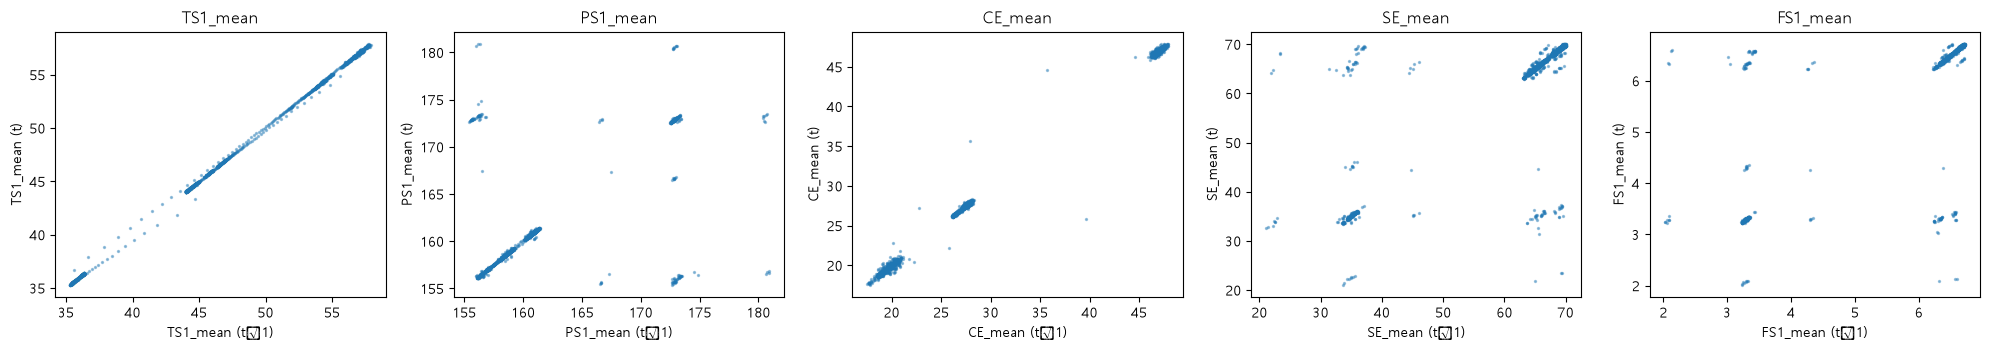

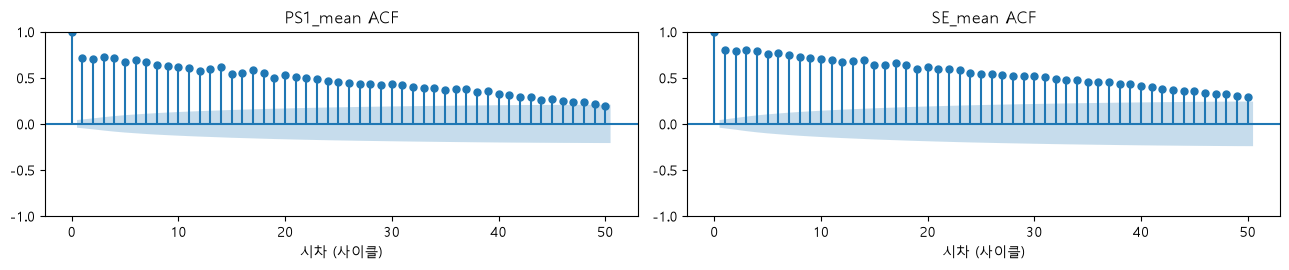

In [2]:
FS = ["TS1_mean", "PS1_mean", "CE_mean", "SE_mean", "FS1_mean"]
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, f in zip(axes, FS):
    ax.scatter(cyc[f].shift(1), cyc[f], s=2, alpha=0.4); ax.set_xlabel(f"{f} (t−1)"); ax.set_ylabel(f"{f} (t)"); ax.set_title(f)
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(13, 2.8)); acf_plot(cyc["PS1_mean"], "PS1_mean ACF", ax=axes[0]); acf_plot(cyc["SE_mean"], "SE_mean ACF", ax=axes[1]); plt.tight_layout(); plt.show()

## 2. 기술통계: 1시차 자기상관

In [3]:
display(pd.Series({f: cyc[f].autocorr(1) for f in FS}, name='1시차 자기상관').round(3).to_frame())

,1시차 자기상관
TS1_mean,1.000
PS1_mean,0.716
CE_mean,0.999
SE_mean,0.805
FS1_mean,0.810


## 3. 가정 확인

Ljung-Box는 "시차 1~k의 자기상관이 모두 0"을 한꺼번에 검정합니다. 특징이 비정상이면 자기상관이 크게 나오기 쉬우므로, 실험 설계(부품 상태 변화) 효과를 빼기 위해 **부품 상태가 전혀 바뀌지 않는 가장 긴 구간**에서도 검정합니다.

In [4]:
key = cyc[list(COMP)].astype(str).agg("-".join, axis=1); run = (key != key.shift()).cumsum()
seg = cyc[run == run.value_counts().idxmax()]
print(f"부품 상태 고정 구간: 사이클 {seg.cycle.min()}~{seg.cycle.max()} ({len(seg)}개), 상태 {key[seg.index[0]]}")

부품 상태 고정 구간: 사이클 0~209 (210개), 상태 3-100-0-130


## 4. 정상성 확인

사이클 순서대로 본 이 특징이 **정상(평균·분산이 시간에 따라 일정)**인지 확인합니다. ADF(H0: 비정상)와 KPSS(H0: 정상)는 질문이 반대라서 함께 봅니다.

- 비정상이거나 자기상관이 크면 "관측값이 서로 독립"이라는 검정의 가정이 약해집니다. 그래서 7단계에서 **50사이클 블록 평균으로 다시 검정**합니다.
- KPSS p가 0.01이나 0.10으로 나오면 경계값입니다. 각각 "0.01 이하", "0.10 이상"으로 읽습니다.


,특징,계열,ADF_p,KPSS_p,판정
0,TS1_mean,원값,0.8718,0.010,비정상
1,TS1_mean,1차 차분,0.0000,0.023,추세·구조변화(둘 다 기각)
2,PS1_mean,원값,0.0002,0.100,정상
3,PS1_mean,1차 차분,0.0000,0.100,정상
4,CE_mean,원값,0.8326,0.010,비정상
5,CE_mean,1차 차분,0.0000,0.100,정상
6,SE_mean,원값,0.0008,0.010,추세·구조변화(둘 다 기각)
7,SE_mean,1차 차분,0.0000,0.100,정상
8,FS1_mean,원값,0.0021,0.010,추세·구조변화(둘 다 기각)
9,FS1_mean,1차 차분,0.0000,0.100,정상


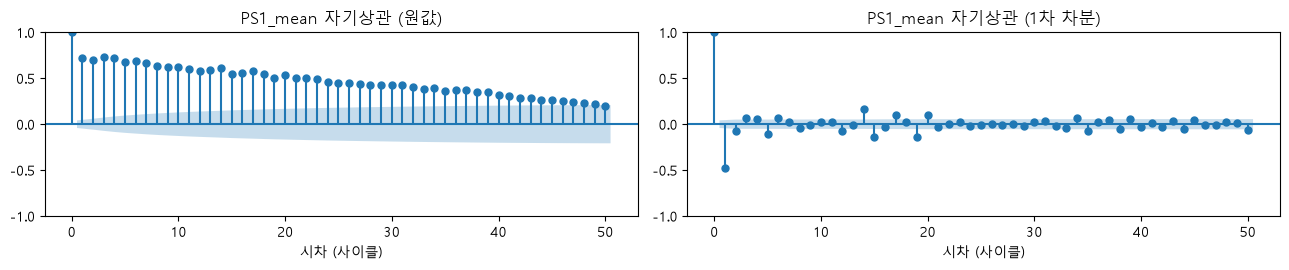

In [5]:
st = stationarity(cyc, ['TS1_mean', 'PS1_mean', 'CE_mean', 'SE_mean', 'FS1_mean'])
display(st.style.format({"ADF_p": "{:.4f}", "KPSS_p": "{:.3f}"}))
fig, axes = plt.subplots(1, 2, figsize=(13, 2.8))
acf_plot(cyc['PS1_mean'], "PS1_mean 자기상관 (원값)", ax=axes[0])
acf_plot(cyc['PS1_mean'].diff(), "PS1_mean 자기상관 (1차 차분)", ax=axes[1])
plt.tight_layout(); plt.show()

## 5. 가설검정 (p-값) — Ljung-Box

In [6]:
from statsmodels.stats.diagnostic import acorr_ljungbox
rows = []
for f in FS:
    for scope, x in [("전체", cyc[f]), (f"고정 구간({len(seg)})", seg[f])]:
        lb = acorr_ljungbox(x.dropna(), lags=[10, 20])
        rows.append(dict(특징=f, 범위=scope, Q10=lb.lb_stat.iloc[0], p10=lb.lb_pvalue.iloc[0], Q20=lb.lb_stat.iloc[1], p20=lb.lb_pvalue.iloc[1], 자기상관1=x.autocorr(1)))
lbt = pd.DataFrame(rows); lbt["p10_holm"] = holm(lbt["p10"])
display(lbt.style.format({"Q10": "{:.0f}", "Q20": "{:.0f}", "p10": "{:.2e}", "p20": "{:.2e}", "p10_holm": "{:.2e}", "자기상관1": "{:.3f}"}))

,특징,범위,Q10,p10,Q20,p20,자기상관1,p10_holm
0,TS1_mean,전체,21908,0.00e+00,43462,0.00e+00,1.000,0.00e+00
1,TS1_mean,고정 구간(210),1209,1.61e-253,1661,0.00e+00,1.000,6.44e-253
2,PS1_mean,전체,10194,0.00e+00,17298,0.00e+00,0.716,0.00e+00
3,PS1_mean,고정 구간(210),1355,5.55e-285,1952,0.00e+00,0.998,2.78e-284
4,CE_mean,전체,21787,0.00e+00,43043,0.00e+00,0.999,0.00e+00
5,CE_mean,고정 구간(210),90,5.28e-15,91,4.47e-11,0.831,5.28e-15
6,SE_mean,전체,12889,0.00e+00,22390,0.00e+00,0.805,0.00e+00
7,SE_mean,고정 구간(210),762,2.59e-157,958,4.02e-190,0.754,5.18e-157
8,FS1_mean,전체,13282,0.00e+00,23421,0.00e+00,0.810,0.00e+00
9,FS1_mean,고정 구간(210),1042,2.03e-217,1509,4.02e-308,0.905,6.09e-217


## 6. 효과 크기: 유효 표본 수

자기상관이 ρ(1시차)인 AR(1) 근사에서 **유효 표본 수 ≈ n × (1 − ρ) / (1 + ρ)**입니다. 실제로 서로 독립인 표본이 몇 개쯤인지 알려 줍니다.

In [7]:
n = len(cyc)
neff = pd.DataFrame([dict(특징=f, 자기상관1=cyc[f].autocorr(1), 유효표본수=n * (1 - cyc[f].autocorr(1)) / (1 + cyc[f].autocorr(1))) for f in FS])
display(neff.style.format({"자기상관1": "{:.3f}", "유효표본수": "{:.0f}"}))

,특징,자기상관1,유효표본수
0,TS1_mean,1.000,0
1,PS1_mean,0.716,365
2,CE_mean,0.999,1
3,SE_mean,0.805,239
4,FS1_mean,0.810,231


## 7. 블록 단위 재확인

50사이클 블록 평균끼리도 자기상관이 남는지 봅니다.

In [8]:
bm = cyc.assign(block=cyc["cycle"] // BLOCK).groupby("block")[FS].mean()
display(pd.Series({f: bm[f].autocorr(1) for f in FS}, name="블록 평균의 1시차 자기상관").round(3).to_frame())

,블록 평균의 1시차 자기상관
TS1_mean,0.978
PS1_mean,0.535
CE_mean,0.980
SE_mean,0.601
FS1_mean,0.654


## 8. 최종 판정

In [9]:
all_sig = (lbt["p10_holm"] < ALPHA).all()
final = pd.DataFrame([dict(가설="H06", 검정="Ljung-Box (시차 10)", 통계량=f"Q 최대 {lbt.Q10.max():.0f}", p_holm_최대=lbt.p10_holm.max(),
    효과크기=f"1시차 자기상관 {lbt.loc[lbt.범위 == '전체', '자기상관1'].min():.2f}~{lbt.loc[lbt.범위 == '전체', '자기상관1'].max():.2f}",
    유효표본수_최소=round(float(neff.유효표본수.min()), 1), 판정="H0 기각" if all_sig else "일부 H0 유지")])
display(final)
save_result("H06", title="사이클 간 자기상관", test="Ljung-Box", stat=final.통계량[0], p=float(lbt.p10_holm.max()),
            effect=final.효과크기[0], verdict=final.판정[0])

,가설,검정,통계량,p_holm_최대,효과크기,유효표본수_최소,판정
0,H06,Ljung-Box (시차 10),Q 최대 21908,5.276645e-15,1시차 자기상관 0.72~1.00,0.1,H0 기각


저장: results/H06.json


## 9. 해석과 결정

- 모든 특징에서 자기상관이 매우 강합니다(1시차 0.72~1.00). **부품 상태가 고정된 구간에서도** 그렇습니다. 실험 설계 때문만이 아니라 온도 같은 운전 조건이 천천히 변하기 때문입니다.
- 유효 표본 수는 2,205개보다 훨씬 작습니다. 온도처럼 자기상관이 1에 가까운 특징은 실제로 독립인 표본이 몇 개 되지 않습니다.
- **결정:**
  1. 무작위로 섞어 평가하면 쌍둥이 같은 이웃 사이클이 학습과 시험에 함께 들어가 점수가 부풀려집니다. **순서 블록 분할을 평가 기준**으로 씁니다.
  2. 다른 가설에서 블록 평균으로 재확인하는 이유이기도 합니다.